# Import Libraries

In [2]:
%pip install pandas sqlalchemy pymysql python-dotenv matplotlib seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlalchemy
import pymysql
import dotenv

# Connect to MySQL Database

In [2]:
from dotenv import load_dotenv  # Load settings from the .env file
import os  # Access environment variables
from pathlib import Path  # Check whether the file exists

# Check whether .env exists in the current working directory
print(".env file exists:", Path(".env").exists())

# Load environment variables from the current folder
load_dotenv(override=True)

# Check whether database settings loaded successfully
print("Username loaded:", bool(os.getenv("DB_USER")))
print("Database:", os.getenv("DB_NAME"))
print("Password loaded:", bool(os.getenv("DB_PASSWORD")))

.env file exists: False
Username loaded: True
Database: hospital_db
Password loaded: True


In [3]:
import os  # Access database credentials
from dotenv import load_dotenv  # Load settings from .env
from sqlalchemy import create_engine, text  # Create and test the MySQL connection
from urllib.parse import quote_plus  # Safely encode special characters in the password

# Load database settings from the .env file in the current folder
load_dotenv(override=True)

# Read database credentials
user = os.getenv("DB_USER")  # MySQL username
password = quote_plus(os.getenv("DB_PASSWORD", ""))  # Encode password safely
host = os.getenv("DB_HOST", "localhost")  # Use localhost if no host is specified
port = os.getenv("DB_PORT", "3306")  # Use the default MySQL port if not specified
database = os.getenv("DB_NAME", "hospital_db")  # Read the database name

# Create the SQLAlchemy engine for connecting Python to MySQL
engine = create_engine(
    f"mysql+pymysql://{user}:{password}@{host}:{port}/{database}"
)

# Open a connection and check which database is connected
with engine.connect() as conn:
    result = conn.execute(text("SELECT DATABASE()"))  # Get the current database name
    print("Connected database:", result.scalar())  # Display the connection result

Connected database: hospital_db


## Load Patient Data

In [4]:
# Load patient data from MySQL into Python
patients_df = pd.read_sql("SELECT * FROM patients", engine)

# Display the first five rows
patients_df.head(5)

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,002bc307-2fff-04ba-161b-98cce123e226,1933-08-13,None,Mrs.,Lavonia8,Wunsch504,None,Will178,M,white,nonhispanic,F,Monson Center Massachusetts US,1068 Quitzon Station,Quincy,Massachusetts,Norfolk County,02171,42.288619,-70.958765
1,0034fe01-207f-275f-6b4b-821f7b0af044,1984-01-27,None,Mrs.,Sharice315,Johnston597,None,Yundt842,M,asian,nonhispanic,F,Brookline Massachusetts US,641 Okuneva Dale Apt 41,Quincy,Massachusetts,Norfolk County,02186,42.316407,-70.968590
2,00abe029-00fa-a666-34f5-258a36978f6d,1962-08-08,None,Mrs.,Lourdes258,Torres807,None,Santacruz647,M,white,hispanic,F,Caguas Puerto Rico PR,1083 Kris View Unit 89,Weymouth,Massachusetts,Norfolk County,,42.244103,-70.986878
3,010ff9c1-564b-6e32-09f4-29cb4224bba9,1952-11-02,None,Mr.,Margarito178,Berge125,None,,M,white,nonhispanic,M,Brockton Massachusetts US,540 Romaguera Gate,Boston,Massachusetts,Suffolk County,02203,42.376160,-71.052651
4,01274098-150f-8211-6150-29f2a2da266c,1929-05-15,None,Mrs.,Corrin41,Heaney114,None,Mayert710,M,white,nonhispanic,F,Georgetown Massachusetts US,294 Hegmann Branch Suite 96,Boston,Massachusetts,Suffolk County,02129,42.320931,-71.003087


## Load Encounters Data

In [5]:
# Load the encounters table from MySQL
encounters_df = pd.read_sql("SELECT * FROM encounters", engine)

# Display the first five rows
encounters_df.head(5)

,Id,START,STOP,PATIENT,ORGANIZATION,PAYER,ENCOUNTERCLASS,CODE,DESCRIPTION,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE,REASONCODE,REASONDESCRIPTION
0,0002c38a-54e9-0788-930a-90900dce3612,2011-08-07 09:46:50,2011-08-07 10:01:50,5e129b38-3d63-3692-2a53-c2b56f9d8af0,d78e84ec-30aa-3bba-a33a-f29a3a454662,6e2f1a2d-27bd-3701-8d08-dae202c58632,ambulatory,185349003,Encounter for check-up,85.55,10224.23,6936.92,None,None
1,00059b24-6473-ca4a-8795-7373d4ddc7e0,2021-07-15 08:58:01,2021-07-15 09:13:01,45b87421-394d-6654-4d81-6cb5b165e455,d78e84ec-30aa-3bba-a33a-f29a3a454662,6e2f1a2d-27bd-3701-8d08-dae202c58632,outpatient,33879002,Administration of vaccine to produce active im...,142.58,278.58,152.69,None,None
2,00091c5b-f3a1-ee7b-88cc-850c746f8f58,2013-07-29 01:06:15,2013-07-29 01:21:15,1712d26d-822d-1e3a-2267-0a9dba31d7c8,d78e84ec-30aa-3bba-a33a-f29a3a454662,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,outpatient,185349003,Encounter for check up (procedure),85.55,85.55,0.00,None,None
3,00092210-7294-428e-1334-9d3f4b671ca4,2020-11-05 02:41:24,2020-11-05 02:56:24,41a6be0c-6388-3b28-daff-dc60e5d6d61b,d78e84ec-30aa-3bba-a33a-f29a3a454662,b3221cfc-24fb-339e-823d-bc4136cbc4ed,ambulatory,448337001,Telemedicine consultation with patient,142.58,142.58,40.45,88805009,Chronic congestive heart failure (disorder)
4,000cc8f4-f2c7-5cf3-419d-13be23d959da,2012-10-17 02:54:11,2012-10-17 03:09:11,442dc617-c7f2-0513-15cd-c35c4efdba73,d78e84ec-30aa-3bba-a33a-f29a3a454662,7caa7254-5050-3b5e-9eae-bd5ea30e809c,wellness,162673000,General examination of patient (procedure),136.80,1597.43,1187.02,None,None


## Load Payers Data

In [6]:
# Load payer data from MySQL into Python
payers_df = pd.read_sql("SELECT * FROM payers", engine)

# Display the first five rows of payer data
payers_df.head(5)

,Id,NAME,ADDRESS,CITY,STATE_HEADQUARTERED,ZIP,PHONE
0,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health,900 Cottage Grove Rd,Bloomfield,CT,06002,1-800-997-1654
1,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem,220 Virginia Ave,Indianapolis,IN,46204,1-800-331-1476
2,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna,151 Farmington Ave,Hartford,CT,06156,1-800-872-3862
3,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare,9800 Healthcare Lane,Minnetonka,MN,55436,1-888-545-5205
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield,Michigan Plaza,Chicago,IL,60007,1-800-262-2583


## Load Procedures Data

In [7]:
# Load procedure data from MySQL into Python
procedures_df = pd.read_sql("SELECT * FROM procedures", engine)

# Display the first five rows of procedure data
procedures_df.head(5)

,START,STOP,PATIENT,ENCOUNTER,CODE,DESCRIPTION,BASE_COST,REASONCODE,REASONDESCRIPTION
0,2011-01-02 09:26:36,2011-01-02 12:58:36,3de74169-7f67-9304-91d4-757e0f3a14d2,32c84703-2481-49cd-d571-3899d5820253,265764009,Renal dialysis (procedure),903,None,None
1,2011-01-03 05:44:39,2011-01-03 06:01:42,d9ec2e44-32e9-9148-179a-1653348cc4e2,c98059da-320a-c0a6-fced-c8815f3e3f39,76601001,Intramuscular injection,2477,None,None
2,2011-01-04 14:49:55,2011-01-04 15:04:55,d856d6e6-4c98-e7a2-129b-44076c63d008,2cfd4ddd-ad13-fe1e-528b-15051cea2ec3,703423002,Combined chemotherapy and radiation therapy (p...,11620,None,None
3,2011-01-05 04:02:09,2011-01-05 04:17:09,bc9d59c3-0a30-6e3b-f47d-022e4f03c8de,17966936-0878-f4db-128b-a43ae10d0878,173160006,Diagnostic fiberoptic bronchoscopy (procedure),9796,None,None
4,2011-01-05 12:58:36,2011-01-05 16:42:36,3de74169-7f67-9304-91d4-757e0f3a14d2,9de5f0b0-4ba4-ce6f-45fb-b55c202f31a5,265764009,Renal dialysis (procedure),1255,None,None


## Load Organizations Data

In [8]:
# Load organization data from MySQL into Python
organizations_df = pd.read_sql("SELECT * FROM organizations", engine)

# Display the first five rows of organization data
organizations_df.head(5)

,Id,NAME,ADDRESS,CITY,STATE,ZIP,LAT,LON
0,d78e84ec-30aa-3bba-a33a-f29a3a454662,MASSACHUSETTS GENERAL HOSPITAL,55 FRUIT STREET,BOSTON,MA,02114,42.362813,-71.069187


## Check Dataset Shape

In [9]:
# Display the number of rows and columns in the patients table
print("Patients:", patients_df.shape)

# Display the number of rows and columns in the encounters table
print("Encounters:", encounters_df.shape)

# Display the number of rows and columns in the payers table
print("Payers:", payers_df.shape)

# Display the number of rows and columns in the procedures table
print("Procedures:", procedures_df.shape)

# Display the number of rows and columns in the organizations table
print("Organizations:", organizations_df.shape)

Patients: (973, 20)
Encounters: (27891, 14)
Payers: (10, 7)
Procedures: (47701, 9)
Organizations: (1, 8)


## Check Columns Name 

In [10]:
# Display column names from the patients table
print("Patients Columns:")
print(patients_df.columns.tolist())

# Display column names from the encounters table
print("\nEncounters Columns:")
print(encounters_df.columns.tolist())

# Display column names from the payers table
print("\nPayers Columns:")
print(payers_df.columns.tolist())

# Display column names from the procedures table
print("\nProcedures Columns:")
print(procedures_df.columns.tolist())

# Display column names from the organizations table
print("\nOrganizations Columns:")
print(organizations_df.columns.tolist())

Patients Columns:
['Id', 'BIRTHDATE', 'DEATHDATE', 'PREFIX', 'FIRST', 'LAST', 'SUFFIX', 'MAIDEN', 'MARITAL', 'RACE', 'ETHNICITY', 'GENDER', 'BIRTHPLACE', 'ADDRESS', 'CITY', 'STATE', 'COUNTY', 'ZIP', 'LAT', 'LON']

Encounters Columns:
['Id', 'START', 'STOP', 'PATIENT', 'ORGANIZATION', 'PAYER', 'ENCOUNTERCLASS', 'CODE', 'DESCRIPTION', 'BASE_ENCOUNTER_COST', 'TOTAL_CLAIM_COST', 'PAYER_COVERAGE', 'REASONCODE', 'REASONDESCRIPTION']

Payers Columns:
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE_HEADQUARTERED', 'ZIP', 'PHONE']

Procedures Columns:
['START', 'STOP', 'PATIENT', 'ENCOUNTER', 'CODE', 'DESCRIPTION', 'BASE_COST', 'REASONCODE', 'REASONDESCRIPTION']

Organizations Columns:
['Id', 'NAME', 'ADDRESS', 'CITY', 'STATE', 'ZIP', 'LAT', 'LON']


## Check Missing Values Patients

In [11]:
# Count missing values in each column of the patients table
print("Patients Missing Values:")
print(patients_df.isnull().sum())

Patients Missing Values:
Id              0
BIRTHDATE       0
DEATHDATE     973
PREFIX          0
FIRST           0
LAST            0
SUFFIX        973
MAIDEN          0
MARITAL         0
RACE            0
ETHNICITY       0
GENDER          0
BIRTHPLACE      0
ADDRESS         0
CITY            0
STATE           0
COUNTY          0
ZIP             0
LAT             0
LON             0
dtype: int64


## Check Missing Values in Encounters

In [12]:
# Display missing values in each column of the encounters table
print("Encounters Missing Values:")
print(encounters_df.isnull().sum())

Encounters Missing Values:
Id                         0
START                      0
STOP                       0
PATIENT                    0
ORGANIZATION               0
PAYER                      0
ENCOUNTERCLASS             0
CODE                       0
DESCRIPTION                0
BASE_ENCOUNTER_COST        0
TOTAL_CLAIM_COST           0
PAYER_COVERAGE             0
REASONCODE             19541
REASONDESCRIPTION      19541
dtype: int64


## Check Missing Values in Payers

In [13]:
# Display missing values in each column of the payers table
print("Payers Missing Values:")
print(payers_df.isnull().sum())

Payers Missing Values:
Id                     0
NAME                   0
ADDRESS                1
CITY                   1
STATE_HEADQUARTERED    1
ZIP                    1
PHONE                  1
dtype: int64


## Check Missing Values in Procedures

In [14]:
# Display missing values in each column of the procedures table
print("Procedures Missing Values:")
print(procedures_df.isnull().sum())

Procedures Missing Values:
START                    0
STOP                     0
PATIENT                  0
ENCOUNTER                0
CODE                     0
DESCRIPTION              0
BASE_COST                0
REASONCODE           47701
REASONDESCRIPTION    47701
dtype: int64


## Check Missing Values in Organizations

In [15]:
# Display missing values in each column of the organizations table
print("Organizations Missing Values:")
print(organizations_df.isnull().sum())

Organizations Missing Values:
Id         0
NAME       0
ADDRESS    0
CITY       0
STATE      0
ZIP        0
LAT        0
LON        0
dtype: int64


## Summary of Missing Values

In [16]:
# Store all five DataFrames in one dictionary
dataframes = {
    "Patients": patients_df,
    "Encounters": encounters_df,
    "Payers": payers_df,
    "Procedures": procedures_df,
    "Organizations": organizations_df
}

# Check the total missing values in each table
for table_name, df in dataframes.items():
    print(table_name, ":", df.isnull().sum().sum(), "missing values")

Patients : 1946 missing values
Encounters : 39082 missing values
Payers : 5 missing values
Procedures : 95402 missing values
Organizations : 0 missing values


## Data Type Checking

In [17]:
# Display data types of all columns in the patients table
print("Patients Data Types:")
print(patients_df.dtypes)

Patients Data Types:
Id             object
BIRTHDATE      object
DEATHDATE      object
PREFIX         object
FIRST          object
LAST           object
SUFFIX         object
MAIDEN         object
MARITAL        object
RACE           object
ETHNICITY      object
GENDER         object
BIRTHPLACE     object
ADDRESS        object
CITY           object
STATE          object
COUNTY         object
ZIP            object
LAT           float64
LON           float64
dtype: object


In [18]:
# Display the data types of all columns in the encounters table
print("Encounters Data Types:")
print(encounters_df.dtypes)

Encounters Data Types:
Id                             object
START                  datetime64[ns]
STOP                   datetime64[ns]
PATIENT                        object
ORGANIZATION                   object
PAYER                          object
ENCOUNTERCLASS                 object
CODE                           object
DESCRIPTION                    object
BASE_ENCOUNTER_COST           float64
TOTAL_CLAIM_COST              float64
PAYER_COVERAGE                float64
REASONCODE                     object
REASONDESCRIPTION              object
dtype: object


In [19]:
# Display the data types of all columns in the payers table
print("Payers Data Types:")
print(payers_df.dtypes)

Payers Data Types:
Id                     object
NAME                   object
ADDRESS                object
CITY                   object
STATE_HEADQUARTERED    object
ZIP                    object
PHONE                  object
dtype: object


In [20]:
# Display the data types of all columns in the procedures table
print("Procedures Data Types:")
print(procedures_df.dtypes)

Procedures Data Types:
START                datetime64[ns]
STOP                 datetime64[ns]
PATIENT                      object
ENCOUNTER                    object
CODE                         object
DESCRIPTION                  object
BASE_COST                     int64
REASONCODE                   object
REASONDESCRIPTION            object
dtype: object


In [21]:
# Display the data types of all columns in the organizations table
print("Organizations Data Types:")
print(organizations_df.dtypes)

Organizations Data Types:
Id          object
NAME        object
ADDRESS     object
CITY        object
STATE       object
ZIP         object
LAT        float64
LON        float64
dtype: object


## Data Cleaning (Patients)

In [22]:
# Convert Date Columns in Patients Table

# Convert BIRTHDATE to datetime format
patients_df["BIRTHDATE"] = pd.to_datetime(
    patients_df["BIRTHDATE"], errors="coerce"
)

# Convert DEATHDATE to datetime format
patients_df["DEATHDATE"] = pd.to_datetime(
    patients_df["DEATHDATE"], errors="coerce"
)

# Display the updated data types of both date columns
print(patients_df[["BIRTHDATE", "DEATHDATE"]].dtypes)

BIRTHDATE    datetime64[ns]
DEATHDATE    datetime64[ns]
dtype: object


In [23]:
# Display the first five rows of the patients table
patients_df.head()

,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,002bc307-2fff-04ba-161b-98cce123e226,1933-08-13,NaT,Mrs.,Lavonia8,Wunsch504,None,Will178,M,white,nonhispanic,F,Monson Center Massachusetts US,1068 Quitzon Station,Quincy,Massachusetts,Norfolk County,02171,42.288619,-70.958765
1,0034fe01-207f-275f-6b4b-821f7b0af044,1984-01-27,NaT,Mrs.,Sharice315,Johnston597,None,Yundt842,M,asian,nonhispanic,F,Brookline Massachusetts US,641 Okuneva Dale Apt 41,Quincy,Massachusetts,Norfolk County,02186,42.316407,-70.968590
2,00abe029-00fa-a666-34f5-258a36978f6d,1962-08-08,NaT,Mrs.,Lourdes258,Torres807,None,Santacruz647,M,white,hispanic,F,Caguas Puerto Rico PR,1083 Kris View Unit 89,Weymouth,Massachusetts,Norfolk County,,42.244103,-70.986878
3,010ff9c1-564b-6e32-09f4-29cb4224bba9,1952-11-02,NaT,Mr.,Margarito178,Berge125,None,,M,white,nonhispanic,M,Brockton Massachusetts US,540 Romaguera Gate,Boston,Massachusetts,Suffolk County,02203,42.376160,-71.052651
4,01274098-150f-8211-6150-29f2a2da266c,1929-05-15,NaT,Mrs.,Corrin41,Heaney114,None,Mayert710,M,white,nonhispanic,F,Georgetown Massachusetts US,294 Hegmann Branch Suite 96,Boston,Massachusetts,Suffolk County,02129,42.320931,-71.003087


In [24]:
# Display the first 10 patient names before cleaning
print(patients_df[["FIRST", "LAST"]].head(10))

          FIRST           LAST
0      Lavonia8      Wunsch504
1    Sharice315    Johnston597
2    Lourdes258      Torres807
3  Margarito178       Berge125
4      Corrin41      Heaney114
5    Tonisha838     Shields502
6     Lyndon118  Jakubowski832
7    Ernesto186       Tapia475
8     Vonnie403    Weissnat378
9     Phylis163       Block661


In [25]:
# Remove Numbers from Patient Names

# Remove trailing numbers from first names in the patients table
patients_df["FIRST"] = patients_df["FIRST"].str.replace(
    r"\d+$", "", regex=True
)

# Remove trailing numbers from last names in the patients table
patients_df["LAST"] = patients_df["LAST"].str.replace(
    r"\d+$", "", regex=True
)

# Remove trailing numbers from maiden names in the patients table
patients_df["MAIDEN"] = patients_df["MAIDEN"].str.replace(
    r"\d+$", "", regex=True
)

# Display the first 10 cleaned patient names
print(patients_df[["FIRST", "MAIDEN", "LAST"]].head(10))

       FIRST     MAIDEN        LAST
0    Lavonia       Will      Wunsch
1    Sharice      Yundt    Johnston
2    Lourdes  Santacruz      Torres
3  Margarito                  Berge
4     Corrin     Mayert      Heaney
5    Tonisha       Bins     Shields
6     Lyndon             Jakubowski
7    Ernesto                  Tapia
8     Vonnie               Weissnat
9     Phylis  Halvorson       Block


In [26]:
# Check Duplicate Records in Patients Table

# Count duplicate rows in the patients table
duplicate_count = patients_df.duplicated().sum()

# Display the total number of duplicate rows
print("Duplicate records in patients table:", duplicate_count)


Duplicate records in patients table: 0


In [27]:
# Check Duplicate Patient IDs

# Count duplicate patient IDs in the patients table
duplicate_patient_ids = patients_df["Id"].duplicated().sum()

# Display the number of duplicate patient IDs
print("Duplicate patient IDs:", duplicate_patient_ids)


Duplicate patient IDs: 0


In [28]:
# Check Missing Values in Patients Table

# Count missing values in each column of the patients table
missing_patients = patients_df.isnull().sum()

# Display only columns that contain missing values
print(missing_patients[missing_patients > 0])

DEATHDATE    973
SUFFIX       973
dtype: int64


In [29]:
# Check the Patients Table After Cleaning

# Display the number of rows and columns in the patients table
print("Patients table shape:", patients_df.shape)

# Display the first five rows after cleaning
display(patients_df.head(5))


Patients table shape: (973, 20)


,Id,BIRTHDATE,DEATHDATE,PREFIX,FIRST,LAST,SUFFIX,MAIDEN,MARITAL,RACE,ETHNICITY,GENDER,BIRTHPLACE,ADDRESS,CITY,STATE,COUNTY,ZIP,LAT,LON
0,002bc307-2fff-04ba-161b-98cce123e226,1933-08-13,NaT,Mrs.,Lavonia,Wunsch,None,Will,M,white,nonhispanic,F,Monson Center Massachusetts US,1068 Quitzon Station,Quincy,Massachusetts,Norfolk County,02171,42.288619,-70.958765
1,0034fe01-207f-275f-6b4b-821f7b0af044,1984-01-27,NaT,Mrs.,Sharice,Johnston,None,Yundt,M,asian,nonhispanic,F,Brookline Massachusetts US,641 Okuneva Dale Apt 41,Quincy,Massachusetts,Norfolk County,02186,42.316407,-70.968590
2,00abe029-00fa-a666-34f5-258a36978f6d,1962-08-08,NaT,Mrs.,Lourdes,Torres,None,Santacruz,M,white,hispanic,F,Caguas Puerto Rico PR,1083 Kris View Unit 89,Weymouth,Massachusetts,Norfolk County,,42.244103,-70.986878
3,010ff9c1-564b-6e32-09f4-29cb4224bba9,1952-11-02,NaT,Mr.,Margarito,Berge,None,,M,white,nonhispanic,M,Brockton Massachusetts US,540 Romaguera Gate,Boston,Massachusetts,Suffolk County,02203,42.376160,-71.052651
4,01274098-150f-8211-6150-29f2a2da266c,1929-05-15,NaT,Mrs.,Corrin,Heaney,None,Mayert,M,white,nonhispanic,F,Georgetown Massachusetts US,294 Hegmann Branch Suite 96,Boston,Massachusetts,Suffolk County,02129,42.320931,-71.003087


## Data Cleaning (Encounters)

In [30]:
# Check Duplicate Records in the Encounters Table

# Check duplicate rows in the encounters table
duplicate_encounters = encounters_df.duplicated().sum()

# Display the total number of duplicate encounter records
print("Duplicate records in encounters table:", duplicate_encounters)


Duplicate records in encounters table: 0


In [31]:
# Check Duplicate Encounter IDs

# Count duplicate encounter IDs in the encounters table
duplicate_encounter_ids = encounters_df["Id"].duplicated().sum()

# Display the number of duplicate encounter IDs
print("Duplicate encounter IDs:", duplicate_encounter_ids)


Duplicate encounter IDs: 0


In [32]:
# Check Missing Values in the Encounters Table

# Count missing values in each column of the encounters table
missing_encounters = encounters_df.isnull().sum()

# Display only columns that contain missing values
print(missing_encounters[missing_encounters > 0])


REASONCODE           19541
REASONDESCRIPTION    19541
dtype: int64


In [33]:
# Check Missing Values in Important Encounter Columns

# Check missing values in key columns of the encounters table
key_columns = [
    "Id",
    "PATIENT",
    "START",
    "ENCOUNTERCLASS",
    "TOTAL_CLAIM_COST"
]

# Display missing-value counts for these columns
print(encounters_df[key_columns].isnull().sum())


Id                  0
PATIENT             0
START               0
ENCOUNTERCLASS      0
TOTAL_CLAIM_COST    0
dtype: int64


In [34]:
# Check Duplicate Patient References in the Encounters Table

# Get all patient IDs from the patients table
patient_ids = set(patients_df["Id"])

# Find encounter records whose patient ID is absent from the patients table
unmatched_patients = ~encounters_df["PATIENT"].isin(patient_ids)

# Count encounters with unmatched patient IDs
print("Encounters with unmatched patient IDs:",
    unmatched_patients.sum())


Encounters with unmatched patient IDs: 19


In [35]:
# Inspect Unmatched Patient IDs

# Select encounter records whose patient IDs are missing from the patients table
unmatched_encounters = encounters_df[
    ~encounters_df["PATIENT"].isin(patients_df["Id"])
]

# Display the patient IDs and encounter details for the first 10 unmatched records
print(unmatched_encounters[["Id", "PATIENT", "START", "ENCOUNTERCLASS"]].head(10))


                                         Id  \
134    01429d54-cfa4-ad09-0121-28e7c3abfc0e   
2496   1705b39d-ca09-fbd2-a8a3-e144d45b4ba9   
5361   320c272b-5d61-39e3-395d-8c5dca155de0   
6623   3d87d424-23df-92a2-b7e0-5a4950bb6217   
6660   3dc95d30-d47d-bb96-74d2-8381cab130b5   
8189   4be45a85-6d17-7961-42c5-ecb8003454c4   
8983   52ffb5a8-c939-670e-22cb-5c8c88ee62a8   
9439   57094251-f04f-efb4-bfa2-a73ac7c5af2e   
11187  671e99ae-8c4c-7094-e820-da78a25b5674   
15698  8fcfa507-1c60-acd9-a331-94ae6f83e9db   

                                    PATIENT               START ENCOUNTERCLASS  
134    204f8028-72f8-d6f8-761f-79ebf9f02311 2019-06-26 11:17:46       wellness  
2496   204f8028-72f8-d6f8-761f-79ebf9f02311 2013-02-06 11:17:46     outpatient  
5361   204f8028-72f8-d6f8-761f-79ebf9f02311 2017-06-14 11:17:46       wellness  
6623   204f8028-72f8-d6f8-761f-79ebf9f02311 2011-05-11 11:17:46       wellness  
6660   204f8028-72f8-d6f8-761f-79ebf9f02311 2021-04-21 11:17:46     outpatien

In [36]:
# Check Whether This Patient Exists in MySQL

# Patient ID found in the unmatched encounters
missing_patient_id = "204f8028-72f8-d6f8-761f-79ebf9f02311"

# Search for this patient ID in the original MySQL patients table
check_patient = pd.read_sql(
    "SELECT Id FROM patients WHERE Id = %s",
    engine,
    params=(missing_patient_id,)
)

# Display the search result
print(check_patient)


Empty DataFrame
Columns: [Id]
Index: []


In [37]:
# Check All 19 Unmatched Records

# Count distinct missing patient IDs among unmatched encounters
unmatched_patient_count = unmatched_encounters["PATIENT"].nunique()

# Count unmatched encounter records
unmatched_encounter_count = len(unmatched_encounters)

# Display both counts
print("Unmatched encounter records:", unmatched_encounter_count)
print("Distinct unmatched patient IDs:", unmatched_patient_count)

# Show how many encounters belong to each unmatched patient ID
print(unmatched_encounters["PATIENT"].value_counts())


Unmatched encounter records: 19
Distinct unmatched patient IDs: 1
PATIENT
204f8028-72f8-d6f8-761f-79ebf9f02311    19
Name: count, dtype: int64


In [38]:
# Check the Encounters Table Shape

# Display the number of rows and columns in the encounters table
print("Encounters table shape:", encounters_df.shape)


Encounters table shape: (27891, 14)


In [39]:
# Check Encounter Date Range

# Find the earliest encounter date in the encounters table
earliest_date = encounters_df["START"].min()

# Find the latest encounter date in the encounters table
latest_date = encounters_df["START"].max()

# Display the date range covered by the data
print("Earliest encounter date:", earliest_date)
print("Latest encounter date:", latest_date)


Earliest encounter date: 2011-01-02 09:26:36
Latest encounter date: 2022-02-05 20:27:36


In [40]:
# Check for Invalid Encounter Dates

# Find encounters whose start date is later than their stop date
invalid_dates = encounters_df[
    encounters_df["START"] > encounters_df["STOP"]
]

# Display the number of encounters with invalid date order
print("Encounters with START after STOP:", len(invalid_dates))

Encounters with START after STOP: 0


In [41]:
# Check Encounter Duration

# Calculate encounter duration in minutes
encounters_df["DURATION_MINUTES"] = (
    encounters_df["STOP"] - encounters_df["START"]
).dt.total_seconds() / 60

# Display the first five encounter durations
print(
    encounters_df[
        ["START", "STOP", "DURATION_MINUTES"]
    ].head(5))

                START                STOP  DURATION_MINUTES
0 2011-08-07 09:46:50 2011-08-07 10:01:50              15.0
1 2021-07-15 08:58:01 2021-07-15 09:13:01              15.0
2 2013-07-29 01:06:15 2013-07-29 01:21:15              15.0
3 2020-11-05 02:41:24 2020-11-05 02:56:24              15.0
4 2012-10-17 02:54:11 2012-10-17 03:09:11              15.0


In [42]:
# Check Encounter Duration Statistics

# Calculate summary statistics for encounter duration in minutes
print(
    encounters_df["DURATION_MINUTES"].describe())


count    2.789100e+04
mean     4.359597e+02
std      2.389942e+04
min      1.500000e+01
25%      1.500000e+01
50%      1.500000e+01
75%      5.185000e+01
max      2.695800e+06
Name: DURATION_MINUTES, dtype: float64


In [43]:
# Find the 10 Longest Encounters

# Select the 10 encounters with the longest calculated durations
longest_encounters = encounters_df.nlargest(
    10, "DURATION_MINUTES"
)

# Display dates, encounter types, and durations for investigation
print(longest_encounters[["Id", "START", "STOP", "ENCOUNTERCLASS", "DURATION_MINUTES"]])


                                         Id               START  \
27498  fc2c2add-0b55-e300-5cea-8f43044eb330 2014-12-17 11:49:08   
4777   2cb41a50-819c-ef7e-87df-b5b47b2e01a1 2014-03-27 00:33:14   
13306  7a19a260-e4a9-7b81-3f93-e07144d634d9 2014-04-02 22:26:28   
6569   3cf29374-f91a-5877-9356-87792501d225 2014-01-31 02:29:54   
10814  63b7c71f-23f5-32dc-b63a-cca7bf5625a2 2014-02-06 02:17:34   
6944   4079872d-73da-3b52-5306-2a978c6f5c8c 2018-07-18 23:56:20   
1805   110777dd-6aca-3c9c-7119-ab2494c0665e 2014-02-06 04:57:58   
507    04df7388-7a70-3e99-c0fe-7f7ddd062931 2014-04-04 22:41:46   
22737  d0476a31-1524-f23f-fb79-290ecd6206aa 2014-01-31 11:10:57   
1817   1123fed5-342e-f49b-4ab9-91f153b9e474 2014-01-31 20:39:04   

                     STOP ENCOUNTERCLASS  DURATION_MINUTES  
27498 2020-02-01 13:49:08     ambulatory      2.695800e+06  
4777  2019-03-13 15:33:14     ambulatory      2.610180e+06  
13306 2015-07-02 13:44:57     ambulatory      6.561185e+05  
6569  2015-04-22 0

In [44]:
# Check Encounter Duration by Visit Type

# Summarize encounter durations by encounter type
duration_by_type = encounters_df.groupby("ENCOUNTERCLASS")[
    "DURATION_MINUTES"
].agg(["count", "median", "mean", "max"])

# Display duration statistics for each encounter type
print(duration_by_type.sort_values("max", ascending=False))


                count  median         mean         max
ENCOUNTERCLASS                                        
ambulatory      12537    15.0   568.765058  2695800.00
outpatient       6300    15.0   352.552317   642240.00
inpatient        1135  1440.0  2210.495154   495000.25
emergency        2322    60.0    92.505319    35340.00
urgentcare       3666    15.0    15.000000       15.00
wellness         1931    15.0    15.000000       15.00


In [45]:
# Count Encounters Lasting More Than 24 Hours

# Count encounters lasting longer than 24 hours
long_duration_count = (
    encounters_df["DURATION_MINUTES"] > 1440 # 24 hours × 60 minutes = 1,440 minutes.
).sum()

# Display the count
print("Encounters longer than 24 hours:", long_duration_count)


Encounters longer than 24 hours: 75


In [46]:
# Inspect Encounters Lasting More Than 24 Hours

# Filter encounters lasting more than 24 hours
long_encounters = encounters_df[
    encounters_df["DURATION_MINUTES"] > 1440
]

# Display the first 10 long-duration encounter records
print(
    long_encounters[
        ["Id", "START", "STOP", "ENCOUNTERCLASS", "DURATION_MINUTES"]
    ].head(10)
)


                                        Id               START  \
120   0124fe17-c895-45df-fb78-1b140ebead00 2020-10-09 07:57:23   
507   04df7388-7a70-3e99-c0fe-7f7ddd062931 2014-04-04 22:41:46   
1042  09f76833-f0db-e4d7-fdbb-2090677e2624 2014-11-02 19:06:02   
1155  0adf72b3-daed-ae69-4917-92f3b5b244dd 2021-01-15 23:26:52   
1177  0b29bad1-7b3c-2585-1b31-c3dd7a6ec36a 2017-09-30 13:44:27   
1263  0c08e08b-f7db-bc9e-44e2-cbc0ee6fc2a5 2017-05-23 06:06:56   
1532  0e7bd07a-c7c2-3515-71c2-c57757430224 2013-08-06 09:32:13   
1805  110777dd-6aca-3c9c-7119-ab2494c0665e 2014-02-06 04:57:58   
1817  1123fed5-342e-f49b-4ab9-91f153b9e474 2014-01-31 20:39:04   
2175  142131dd-5a4a-e328-76ee-3f3457e8a7d8 2014-01-30 17:14:23   

                    STOP ENCOUNTERCLASS  DURATION_MINUTES  
120  2020-10-15 10:41:30      inpatient       8804.116667  
507  2015-01-31 13:54:32     ambulatory     434352.766667  
1042 2014-11-03 19:46:17      inpatient       1480.250000  
1155 2021-01-22 22:42:01      inp

In [47]:
# Check Healthcare Cost Columns

# Check summary statistics for healthcare cost columns
cost_columns = [
    "BASE_ENCOUNTER_COST",
    "TOTAL_CLAIM_COST",
    "PAYER_COVERAGE"
]

# Display count, mean, minimum, maximum, and other statistics
print(encounters_df[cost_columns].describe().T)


                       count         mean          std    min     25%     50%  \
BASE_ENCOUNTER_COST  27891.0   116.181614    28.410082  85.55   85.55  136.80   
TOTAL_CLAIM_COST     27891.0  3639.682174  9205.595748   0.00  142.58  278.58   
PAYER_COVERAGE       27891.0  1114.965652  4768.615576   0.00    0.00   28.44   

                         75%        max  
BASE_ENCOUNTER_COST   142.58     146.18  
TOTAL_CLAIM_COST     1412.53  641882.70  
PAYER_COVERAGE        155.77  247751.42  


In [48]:
# Check zero-cost and zero-coverage records
# Check zero values in the encounters table's cost columns
print("Base encounter cost = 0:",
      (encounters_df["BASE_ENCOUNTER_COST"] == 0).sum())

print("Total claim cost = 0:",
      (encounters_df["TOTAL_CLAIM_COST"] == 0).sum())

print("Payer coverage = 0:",
      (encounters_df["PAYER_COVERAGE"] == 0).sum())

Base encounter cost = 0: 0
Total claim cost = 0: 89
Payer coverage = 0: 13586


In [49]:
# Inspect zero claim cost records
# Filter encounters where total claim cost is zero
zero_claim_cost = encounters_df[
    encounters_df["TOTAL_CLAIM_COST"] == 0
]

# Display the first 10 records for investigation
print(
    zero_claim_cost[
        [
            "Id",
            "START",
            "ENCOUNTERCLASS",
            "BASE_ENCOUNTER_COST",
            "TOTAL_CLAIM_COST",
            "PAYER_COVERAGE"
        ]
    ].head(10)
)

                                        Id               START ENCOUNTERCLASS  \
547   053867c6-4c7b-bacb-4202-fe08b01e7bac 2011-07-15 12:10:53       wellness   
789   07539d48-cf44-ed57-0fba-e214f3047891 2014-01-27 15:44:02       wellness   
1163  0b015f3e-51fe-b09c-6a7a-7807ae1ac6c6 2017-04-09 03:04:48       wellness   
2550  177f2a61-b112-9330-7283-6d09ffe48941 2018-03-30 09:45:55      inpatient   
2668  1885f31a-02aa-5c32-a71d-e5969cbec4ec 2018-05-12 20:40:00       wellness   
2747  193d66eb-8f72-6230-88f8-7d08fbe5a0d5 2014-08-05 15:13:10       wellness   
2767  1975e75b-25cc-9cbd-8a11-88a548530643 2016-04-25 15:44:02       wellness   
3449  1fd0abdc-2218-4cb1-4e03-c00492306681 2013-12-17 04:28:23       wellness   
3905  2476b073-2423-30a7-4c8d-ec6a136c8a40 2014-12-30 15:49:20       wellness   
4098  263fd5cf-1a88-b3e7-c18c-9d2a5a367b00 2016-10-26 09:02:50      inpatient   

      BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST  PAYER_COVERAGE  
547                136.80               0.0   

## Univariate Analysis

### EDA - Encounter Type Analysis


In [50]:
# Count encounters for each encounter type
encounter_counts = encounters_df["ENCOUNTERCLASS"].value_counts()

# Display the count of each encounter type
print(encounter_counts)

ENCOUNTERCLASS
ambulatory    12537
outpatient     6300
urgentcare     3666
emergency      2322
wellness       1931
inpatient      1135
Name: count, dtype: int64


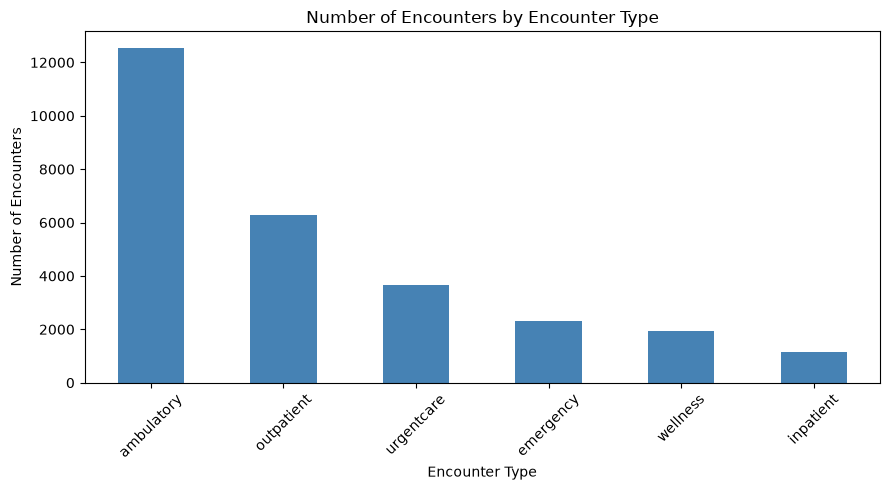

In [51]:
# Create a bar chart for encounter type counts
encounter_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Number of Encounters by Encounter Type")
plt.xlabel("Encounter Type")
plt.ylabel("Number of Encounters")

# Rotate category labels for readability
plt.xticks(rotation=45)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

## Time-Series Analysis - Monthly Encounter Trends


In [52]:
# Extract the year and month from encounter start dates
encounters_df["YEAR_MONTH"] = encounters_df["START"].dt.to_period("M")

# Count encounters for each month
monthly_encounters = encounters_df["YEAR_MONTH"].value_counts().sort_index()

# Display the first 10 months
print(monthly_encounters.head(10))

YEAR_MONTH
2011-01     86
2011-02     86
2011-03    129
2011-04    113
2011-05    131
2011-06    131
2011-07    124
2011-08    115
2011-09    124
2011-10     84
Freq: M, Name: count, dtype: int64


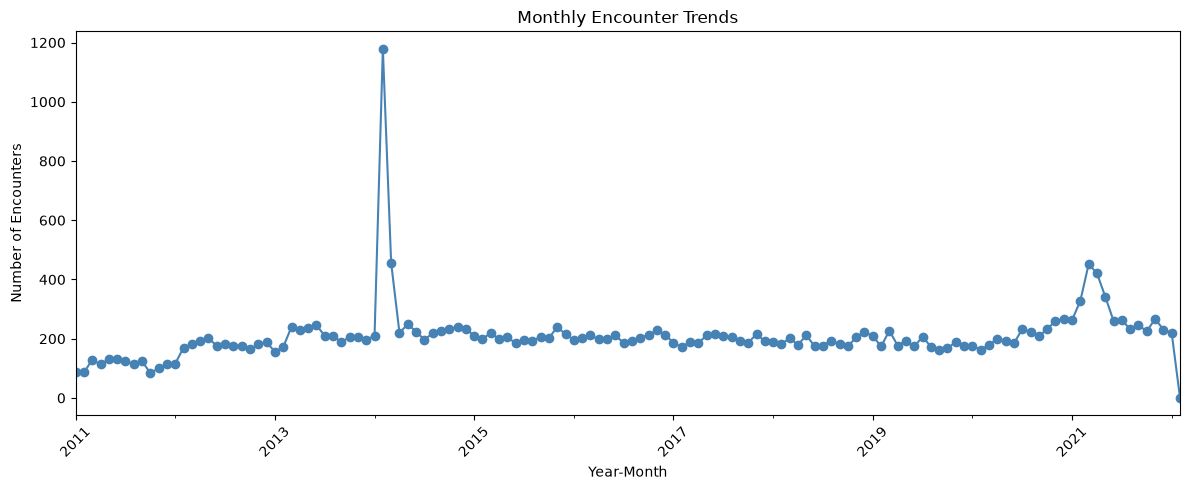

In [53]:
# Create a line chart for monthly encounters
monthly_encounters.plot(
    kind="line",
    figsize=(12, 5),
    marker="o",
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Monthly Encounter Trends")
plt.xlabel("Year-Month")
plt.ylabel("Number of Encounters")

# Rotate date labels for readability
plt.xticks(rotation=45)

# Adjust spacing and display the chart
plt.tight_layout()
plt.show()

In [54]:
# Investigating Low Encounter Count in February 2022

# Check the first and last months in the monthly analysis
print("First month:", monthly_encounters.index.min())
print("Last month:", monthly_encounters.index.max())

# Check the last 5 monthly encounter counts
print(monthly_encounters.tail(5))

First month: 2011-01
Last month: 2022-02
YEAR_MONTH
2021-10    225
2021-11    267
2021-12    231
2022-01    219
2022-02      1
Freq: M, Name: count, dtype: int64


In [55]:
# Highest Encounter Months

# Find the five months with the highest encounter counts
top_months = monthly_encounters.sort_values(
    ascending=False
).head(5)

# Display the top five months
print(top_months)

YEAR_MONTH
2014-02    1179
2014-03     456
2021-03     452
2021-04     421
2021-05     342
Freq: M, Name: count, dtype: int64


In [56]:
# Investigating High Encounter Count in February 2014

# Filter encounters recorded in February 2014
feb_2014 = encounters_df[
    (encounters_df["START"].dt.year == 2014) &
    (encounters_df["START"].dt.month == 2)
]

# Count encounters by type for February 2014
print(feb_2014["ENCOUNTERCLASS"].value_counts())

# Display the total number of encounters
print("Total encounters:", len(feb_2014))

ENCOUNTERCLASS
ambulatory    930
outpatient    188
urgentcare     24
emergency      16
wellness       15
inpatient       6
Name: count, dtype: int64
Total encounters: 1179


## Bivariate Analysis

### EDA - Healthcare Cost by Encounter Type

In [57]:
# Calculate average healthcare costs for each encounter type
cost_by_encounter = encounters_df.groupby("ENCOUNTERCLASS")[
    ["BASE_ENCOUNTER_COST", "TOTAL_CLAIM_COST", "PAYER_COVERAGE"]
].mean().round(2)

# Display average costs by encounter type
print(cost_by_encounter)

                BASE_ENCOUNTER_COST  TOTAL_CLAIM_COST  PAYER_COVERAGE
ENCOUNTERCLASS                                                       
ambulatory                   105.73           2894.11         1029.23
emergency                    145.25           4629.65         1398.29
inpatient                    113.67           7761.35         3250.01
outpatient                   105.04           2237.30          599.64
urgentcare                   142.58           6369.16          834.40
wellness                     136.80           4260.71         2289.88


### EDA - Average Claim Cost by Encounter Type


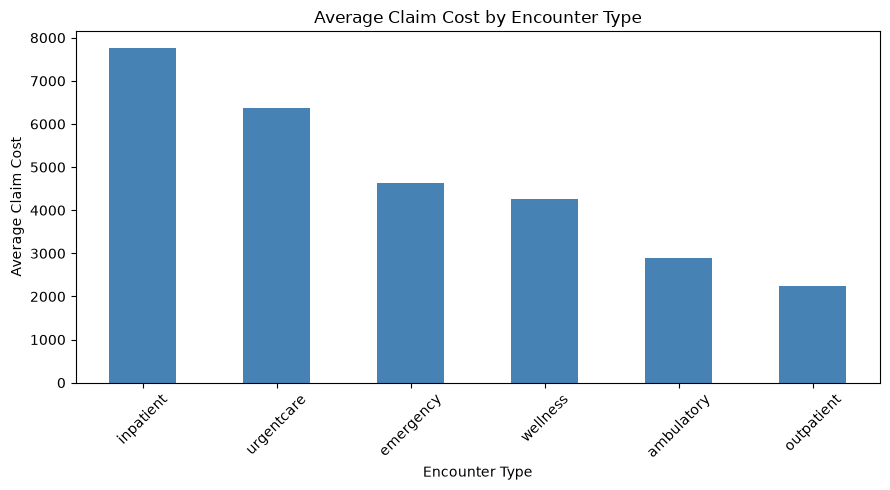

In [58]:
# Sort encounter types by average claim cost
avg_claim_cost = cost_by_encounter["TOTAL_CLAIM_COST"].sort_values(
    ascending=False
)

# Create a bar chart
avg_claim_cost.plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Average Claim Cost by Encounter Type")
plt.xlabel("Encounter Type")
plt.ylabel("Average Claim Cost")

# Rotate labels for readability
plt.xticks(rotation=45)

# Adjust layout and display chart
plt.tight_layout()
plt.show()

### EDA - Average Payer Coverage by Encounter Type


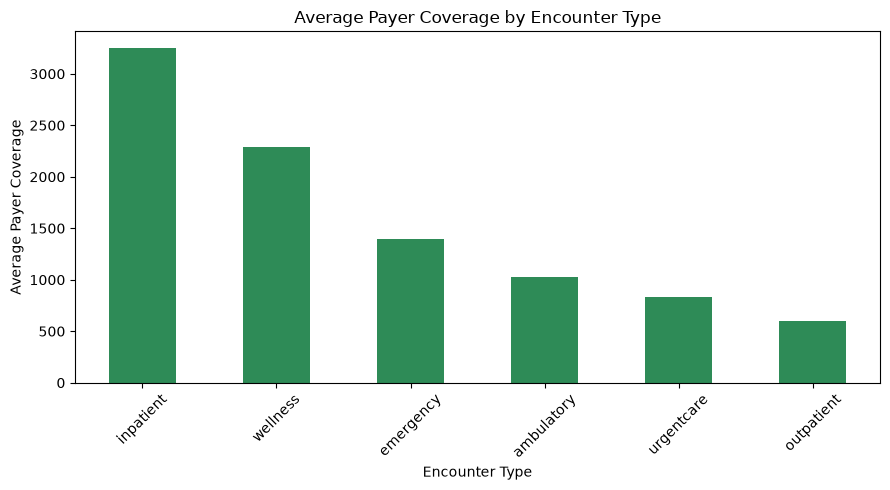

In [59]:
# Calculate average payer coverage and sort from highest to lowest
avg_payer_coverage = cost_by_encounter["PAYER_COVERAGE"].sort_values(
    ascending=False
)

# Create a bar chart
avg_payer_coverage.plot(
    kind="bar",
    figsize=(9, 5),
    color="seagreen"
)

# Add chart title and axis labels
plt.title("Average Payer Coverage by Encounter Type")
plt.xlabel("Encounter Type")
plt.ylabel("Average Payer Coverage")

# Rotate labels for better readability
plt.xticks(rotation=45)

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

### EDA - Encounter Type Summary


In [60]:
# Summarize encounter counts and average costs by encounter type
encounter_summary = encounters_df.groupby("ENCOUNTERCLASS").agg(
    Total_Encounters=("Id", "count"),
    Average_Claim_Cost=("TOTAL_CLAIM_COST", "mean"),
    Average_Payer_Coverage=("PAYER_COVERAGE", "mean")
).round(2)

# Sort by total encounters, highest first
encounter_summary = encounter_summary.sort_values(
    by="Total_Encounters",
    ascending=False
)

# Display the summary table
display(encounter_summary)

,Total_Encounters,Average_Claim_Cost,Average_Payer_Coverage
ENCOUNTERCLASS,,,
ambulatory,12537,2894.11,1029.23
outpatient,6300,2237.30,599.64
urgentcare,3666,6369.16,834.40
emergency,2322,4629.65,1398.29
wellness,1931,4260.71,2289.88
inpatient,1135,7761.35,3250.01


## Univariate Analysis

### EDA - Patient Age Distribution

In [61]:
# Convert birthdate column to datetime format
patients_df["BIRTHDATE"] = pd.to_datetime(
    patients_df["BIRTHDATE"], errors="coerce"
)

# Get today's date
today = pd.Timestamp.today().normalize()

# Calculate patient age in years
patients_df["AGE"] = (
    (today - patients_df["BIRTHDATE"]).dt.days / 365.25
)

# Convert decimal ages to whole numbers, preserving missing values
patients_df["AGE"] = patients_df["AGE"].round(0).astype("Int64")

# Display basic age statistics
display(patients_df["AGE"].describe().round(2))

count    973.0
mean     74.56
std      20.47
min       35.0
25%       57.0
50%       76.0
75%       93.0
max      105.0
Name: AGE, dtype: Float64

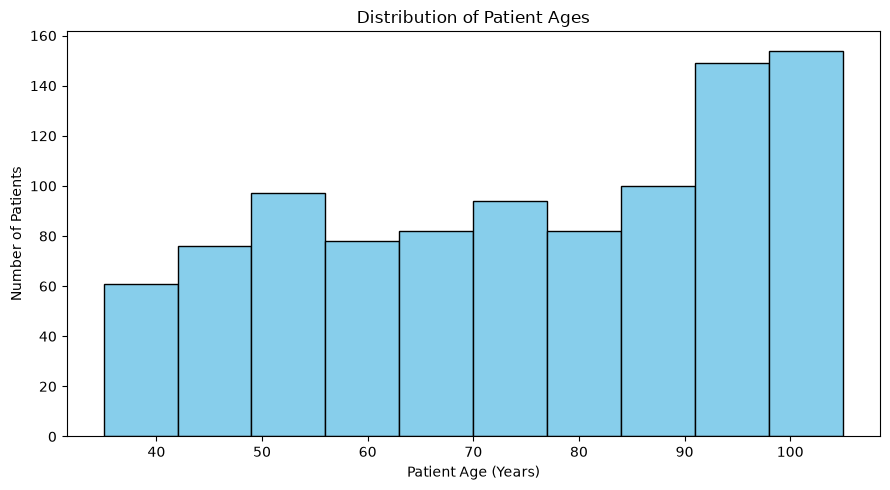

In [62]:
# Create a histogram to show patient age distribution
patients_df["AGE"].dropna().plot(
    kind="hist",
    bins=10,
    figsize=(9, 5),
    edgecolor="black",
    color="skyblue"
)

# Add chart title and axis labels
plt.title("Distribution of Patient Ages")
plt.xlabel("Patient Age (Years)")
plt.ylabel("Number of Patients")

# Display the chart neatly
plt.tight_layout()
plt.show()

### EDA - Most Frequent Medical Procedures

In [63]:
# Count how often each procedure was performed
top_procedures = procedures_df["DESCRIPTION"].value_counts().head(10)

# Display the 10 most frequent procedures
display(top_procedures)

DESCRIPTION
Assessment of health and social care needs (procedure)                                4596
Hospice care (regime/therapy)                                                         4098
Depression screening using Patient Health Questionnaire Two-Item score (procedure)    3614
Depression screening (procedure)                                                      3614
Assessment of substance use (procedure)                                               2906
Renal dialysis (procedure)                                                            2746
Assessment using Morse Fall Scale (procedure)                                         2422
Assessment of anxiety (procedure)                                                     2288
Medication Reconciliation (procedure)                                                 2284
Screening for drug abuse (procedure)                                                  1484
Name: count, dtype: int64

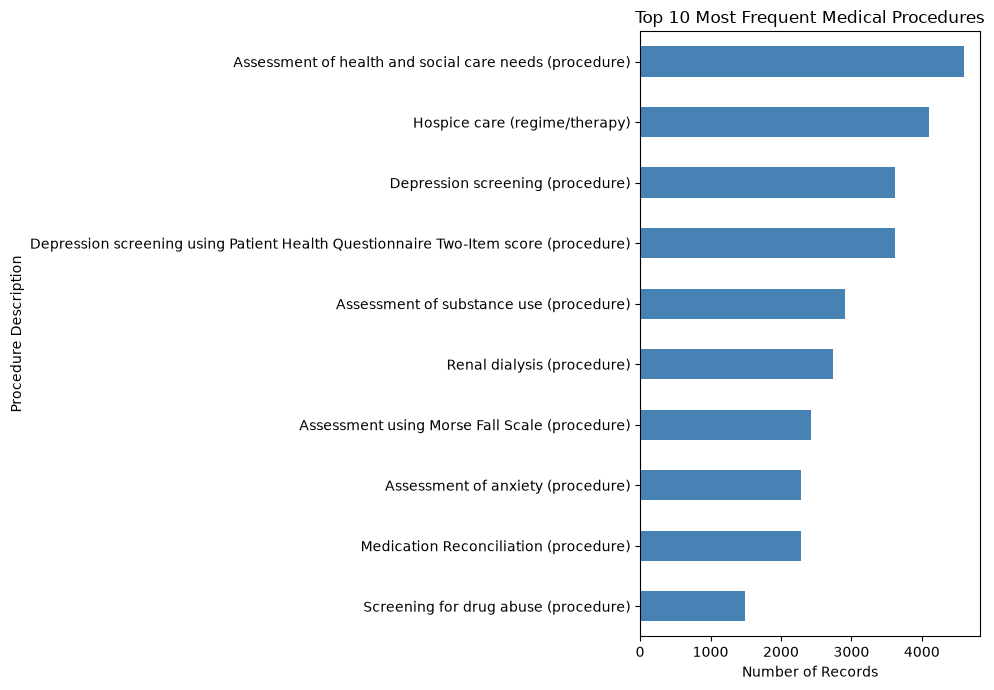

In [64]:
# Get the 10 most frequent procedures
top_procedures = procedures_df["DESCRIPTION"].value_counts().head(10)

# Create a horizontal bar chart
top_procedures.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Top 10 Most Frequent Medical Procedures")
plt.xlabel("Number of Records")
plt.ylabel("Procedure Description")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

## Bivariate Analysis

### EDA - Average Procedure Cost

In [65]:
# Calculate average procedure cost for each description
avg_procedure_cost = procedures_df.groupby("DESCRIPTION")[
    "BASE_COST"
].mean().sort_values(ascending=False)

# Display the 10 procedures with the highest average base cost
display(avg_procedure_cost.head(10).round(2))

DESCRIPTION
Admit to ICU (procedure)                                                           206260.40
Coronary artery bypass grafting                                                     47085.89
Lumpectomy of breast (procedure)                                                    29353.00
Hemodialysis (procedure)                                                            29299.56
Insertion of biventricular implantable cardioverter defibrillator                   27201.00
Electrical cardioversion                                                            25903.11
Partial resection of colon                                                          25229.29
Fine needle aspiration biopsy of lung (procedure)                                   23141.00
Percutaneous mechanical thrombectomy of portal vein using fluoroscopic guidance     20228.04
Percutaneous coronary intervention                                                  19728.00
Name: BASE_COST, dtype: float64

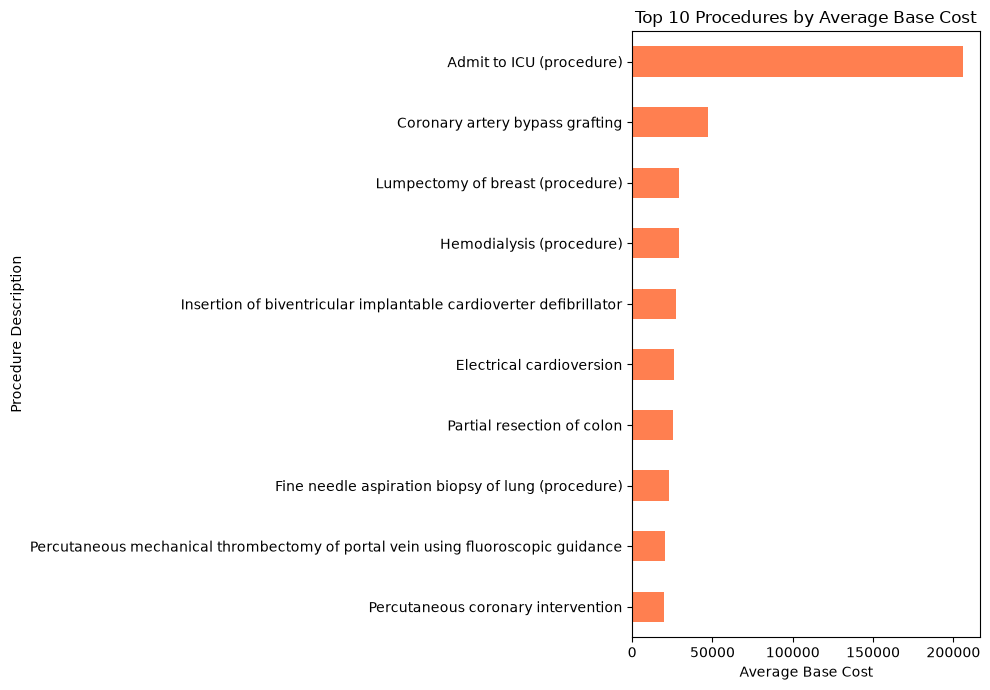

In [66]:
# Select the 10 procedures with the highest average base cost
top_cost_procedures = avg_procedure_cost.head(10)

# Create a horizontal bar chart
top_cost_procedures.sort_values().plot(
    kind="barh",
    figsize=(10, 7),
    color="coral"
)

# Add chart title and axis labels
plt.title("Top 10 Procedures by Average Base Cost")
plt.xlabel("Average Base Cost")
plt.ylabel("Procedure Description")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

## EDA - Insurance Payer Analysis

In [67]:
# Count encounters associated with each payer
payer_summary = encounters_df.groupby("PAYER").agg(
    Total_Encounters=("Id", "count"),
    Average_Claim_Cost=("TOTAL_CLAIM_COST", "mean"),
    Average_Payer_Coverage=("PAYER_COVERAGE", "mean")
).round(2)

# Sort payers by number of encounters
payer_summary = payer_summary.sort_values(
    by="Total_Encounters",
    ascending=False
)

# Display the payer summary
display(payer_summary)

,Total_Encounters,Average_Claim_Cost,Average_Payer_Coverage
PAYER,,,
7caa7254-5050-3b5e-9eae-bd5ea30e809c,11371,2167.55,1689.89
b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,8807,5593.20,0.00
7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,1443,6205.22,5833.66
d47b3510-2895-3b70-9897-342d681c769d,1084,3269.30,1.80
4d71f845-a6a9-3c39-b242-14d25ef86a8d,936,2767.05,1.90
6e2f1a2d-27bd-3701-8d08-dae202c58632,925,3245.58,2242.70
b3221cfc-24fb-339e-823d-bc4136cbc4ed,912,1696.19,1513.93
5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,900,2848.34,4.37
047f6ec3-6215-35eb-9608-f9dda363a44c,809,2996.95,1.20


In [68]:
# Display payer IDs and their names
display(payers_df[["Id", "NAME"]].head(10))

,Id,NAME
0,047f6ec3-6215-35eb-9608-f9dda363a44c,Cigna Health
1,42c4fca7-f8a9-3cd1-982a-dd9751bf3e2a,Anthem
2,4d71f845-a6a9-3c39-b242-14d25ef86a8d,Aetna
3,5059a55e-5d6e-34d1-b6cb-d83d16e57bcf,UnitedHealthcare
4,6e2f1a2d-27bd-3701-8d08-dae202c58632,Blue Cross Blue Shield
5,7c4411ce-02f1-39b5-b9ec-dfbea9ad3c1a,Medicaid
6,7caa7254-5050-3b5e-9eae-bd5ea30e809c,Medicare
7,b1c428d6-4f07-31e0-90f0-68ffa6ff8c76,NO_INSURANCE
8,b3221cfc-24fb-339e-823d-bc4136cbc4ed,Dual Eligible
9,d47b3510-2895-3b70-9897-342d681c769d,Humana


In [69]:
# Create a mapping between payer IDs and payer names
payer_names = payers_df.set_index("Id")["NAME"]

# Replace payer IDs with actual payer names in the summary
payer_summary_named = payer_summary.copy()
payer_summary_named.index = payer_summary_named.index.map(payer_names)

# Display the payer summary with names
display(payer_summary_named)

,Total_Encounters,Average_Claim_Cost,Average_Payer_Coverage
PAYER,,,
Medicare,11371,2167.55,1689.89
NO_INSURANCE,8807,5593.20,0.00
Medicaid,1443,6205.22,5833.66
Humana,1084,3269.30,1.80
Aetna,936,2767.05,1.90
Blue Cross Blue Shield,925,3245.58,2242.70
Dual Eligible,912,1696.19,1513.93
UnitedHealthcare,900,2848.34,4.37
Cigna Health,809,2996.95,1.20


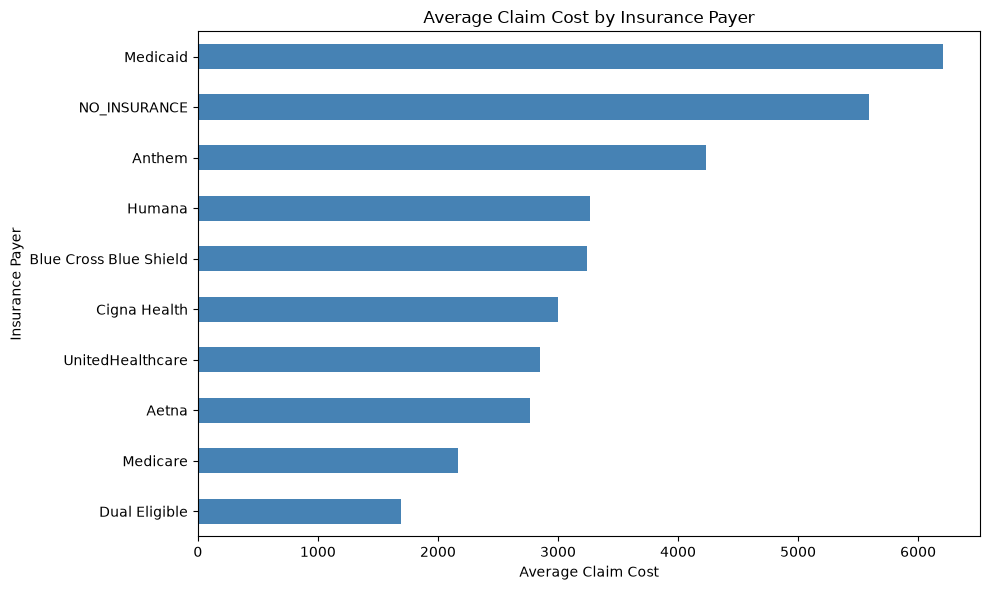

In [70]:
# Sort payers by average claim cost, highest first
avg_claim_by_payer = payer_summary_named[
    "Average_Claim_Cost"
].sort_values(ascending=True)

# Create a horizontal bar chart
avg_claim_by_payer.plot(
    kind="barh",
    figsize=(10, 6),
    color="steelblue"
)

# Add chart title and axis labels
plt.title("Average Claim Cost by Insurance Payer")
plt.xlabel("Average Claim Cost")
plt.ylabel("Insurance Payer")

# Adjust layout and display the chart
plt.tight_layout()
plt.show()

## Multivariate Analysis

### EDA - Encounter Costs and Payer Coverage

,BASE_ENCOUNTER_COST,TOTAL_CLAIM_COST,PAYER_COVERAGE
BASE_ENCOUNTER_COST,1.00,0.13,0.06
TOTAL_CLAIM_COST,0.13,1.00,0.56
PAYER_COVERAGE,0.06,0.56,1.00


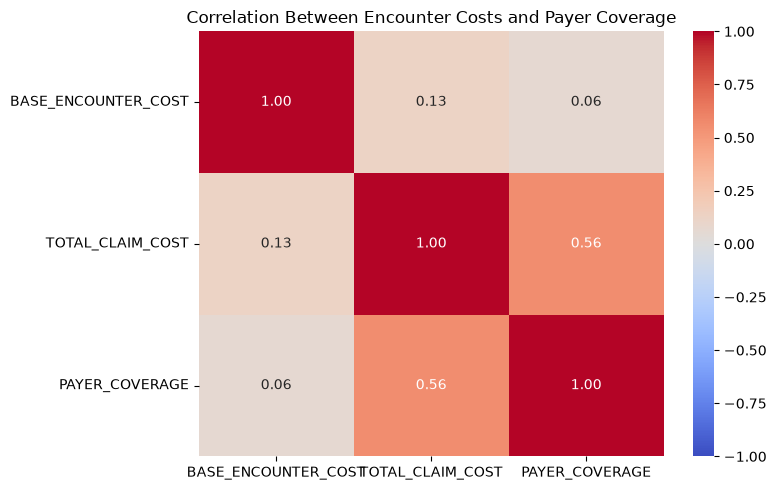

In [71]:
# Select numerical columns for multivariate analysis
cost_columns = [
    "BASE_ENCOUNTER_COST",
    "TOTAL_CLAIM_COST",
    "PAYER_COVERAGE"
]

# Calculate the correlation between the selected columns
correlation_matrix = encounters_df[cost_columns].corr()

# Display the correlation matrix rounded to 2 decimal places
display(correlation_matrix.round(2))

# Create a heatmap to visualize the correlations
plt.figure(figsize=(8, 5))

sns.heatmap(
    correlation_matrix,
    annot=True,       # Display correlation values inside the heatmap
    cmap="coolwarm",  # Use colors to show positive and negative correlations
    vmin=-1,          # Set minimum correlation value
    vmax=1,           # Set maximum correlation value
    fmt=".2f"         # Show values with 2 decimal places
)

# Add a chart title
plt.title("Correlation Between Encounter Costs and Payer Coverage")

# Adjust the chart layout
plt.tight_layout()

# Display the heatmap
plt.show()

### Key Findings

- Base encounter cost and total claim cost show a weak positive correlation of 0.13.
- Base encounter cost and payer coverage show a very weak positive correlation of 0.06.
- Total claim cost and payer coverage show a moderate positive correlation of 0.56.
- Overall, payer coverage tends to increase with total claim cost, although this relationship is not perfect.

**Conclusion:** Total claim cost has a stronger linear relationship with payer coverage than base encounter cost does. Correlation indicates association, not causation.

### EDA - Cost and Coverage by Encounter Type

In [72]:
# Group encounters by encounter type and calculate three metrics
multivariate_summary = encounters_df.groupby("ENCOUNTERCLASS").agg(
    Total_Encounters=("Id", "count"),  # Count encounters in each category
    Average_Base_Cost=("BASE_ENCOUNTER_COST", "mean"),  # Calculate average base cost
    Average_Claim_Cost=("TOTAL_CLAIM_COST", "mean"),  # Calculate average claim cost
    Average_Payer_Coverage=("PAYER_COVERAGE", "mean")  # Calculate average payer coverage
).round(2)

# Sort encounter types by average claim cost, highest first
multivariate_summary = multivariate_summary.sort_values(
    by="Average_Claim_Cost",
    ascending=False
)

# Display the summary table
display(multivariate_summary)

,Total_Encounters,Average_Base_Cost,Average_Claim_Cost,Average_Payer_Coverage
ENCOUNTERCLASS,,,,
inpatient,1135,113.67,7761.35,3250.01
urgentcare,3666,142.58,6369.16,834.40
emergency,2322,145.25,4629.65,1398.29
wellness,1931,136.80,4260.71,2289.88
ambulatory,12537,105.73,2894.11,1029.23
outpatient,6300,105.04,2237.30,599.64


### Key Findings

- Inpatient encounters have the highest average claim cost at 7761.35.
- Urgent care has the second-highest average claim cost at 6369.16.
- Ambulatory encounters have the highest encounter volume, with 12,537 encounters.
- Outpatient encounters have the lowest average claim cost at 2237.30.
- Average payer coverage varies across encounter types, with inpatient showing the highest average coverage at 3250.01.

**Conclusion:** Comparing encounter volume, average claim cost, and average payer coverage together helps identify differences in healthcare utilization and costs across encounter types.

## Final Data Quality Check

In [73]:
# Store all datasets in one dictionary
datasets = {
    "Patients": patients_df,
    "Encounters": encounters_df,
    "Procedures": procedures_df,
    "Payers": payers_df,
    "Organizations": organizations_df
}

# Collect data quality information for each dataset
quality_summary = []

for name, df in datasets.items():

    # Count missing values across all columns
    missing_values = df.isnull().sum().sum()

    # Count completely duplicated rows
    duplicate_rows = df.duplicated().sum()

    # Store the results
    quality_summary.append({
        "Dataset": name,
        "Total_Rows": len(df),
        "Total_Columns": len(df.columns),
        "Missing_Values": missing_values,
        "Duplicate_Rows": duplicate_rows
    })

# Display the final data quality report
quality_df = pd.DataFrame(quality_summary)
display(quality_df)

,Dataset,Total_Rows,Total_Columns,Missing_Values,Duplicate_Rows
0,Patients,973,21,1946,0
1,Encounters,27891,16,39082,0
2,Procedures,47701,9,95402,0
3,Payers,10,7,5,0
4,Organizations,1,8,0,0


## EDA - Key Findings and Conclusion

### Key Findings

1. **Encounter Analysis:** Ambulatory encounters were the most frequent, with 12,537 records.
2. **Monthly Trends:** February 2014 had the highest monthly encounter count, with 1,179 records. Most were ambulatory encounters.
3. **Healthcare Costs:** Inpatient encounters had the highest average claim cost at 7,761.35, while outpatient encounters had the lowest at 2,237.30.
4. **Payer Coverage:** Inpatient encounters had the highest average payer coverage at 3,250.01.
5. **Patient Age:** The average estimated current patient age was 74.53 years.
6. **Procedure Analysis:** Assessment of health and social care needs was the most frequently recorded procedure, with 4,596 records.
7. **Procedure Costs:** Admit to ICU had the highest average procedure base cost at 206,260.40.
8. **Insurance Payers:** Medicaid had the highest average claim cost at 6,205.22, while Medicare had the highest encounter count at 11,371.

### Conclusion

Python EDA helped identify encounter patterns, monthly trends, healthcare costs, patient age distribution, frequently recorded procedures, and payer-level differences. These findings can support further investigation and help build an interactive Power BI dashboard for healthcare data analysis.

*Note: Currency units have not been confirmed. Patient age is estimated using the current date, not the encounter date.*